Seguros Altavida es una compañía de seguros que administra el aseguramiento en salud de sus 
afiliados. El área de Transformación Operacional analiza las autorizaciones de prestaciones 
(procedimientos y medicamentos) para apoyar la toma de decisiones sobre cobertura, costo 
calidad de la operación. y Recientemente, la operación reportó inconsistencias en la información y la 
necesidad de relacionar el gasto autorizado con el perfil salarial de los afiliados.  

In [1]:
# cargo las librerias que necesito
import pandas as pd
import numpy as np
import sqlite3 as sql 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# cargo las bases de datos 
# cargo base de datos de autorizaciones
df_autorizaciones = pd.read_csv("BaseAutorizaciones.txt", sep="\t")  #/t por q es tabular
df_autorizaciones.head()

,Afiliado_Id,Autorizacion_id,Fecha,Tipo_Prestacion,Prestacion_id,Valor_Prestacion,Estado_Autorizacion
0,18647965,657260903,2023-05-02,PROCEDIMIENTO EPS,46101,31200.0,ENTREGADA
1,19112491,657443085,2023-05-03,PROCEDIMIENTO EPS,29555,37285.0,ANULADA
2,10540019,659155460,2023-05-09,PROCEDIMIENTO EPS,174788,98782.0,ENTREGADA
3,21997185,658340814,2023-05-05,PROCEDIMIENTO EPS,178385,24060.0,ENTREGADA
4,1527007,657994534,2023-05-04,PROCEDIMIENTO EPS,51711,7500.0,GENERADA


In [3]:
# cargo los datos de salario
df_salario = pd.read_csv("BaseSalario.txt", sep=",")  #, por q esta separado por coma
df_salario.head()

,Afiliado,salario
0,18647965,2500000
1,19112491,3160000
2,10540019,1700000
3,21997185,1300000
4,1527007,3160000


In [4]:
# busco datos nulos es salario
df_salario.isnull().sum()

Afiliado    0
salario     0
dtype: int64

In [5]:
# busco datos nulos  en las autorizaciones
df_autorizaciones.isnull().sum()

Afiliado_Id            0
Autorizacion_id        0
Fecha                  0
Tipo_Prestacion        0
Prestacion_id          0
Valor_Prestacion       0
Estado_Autorizacion    0
dtype: int64

In [6]:
# quito epacios de los nombres de las columna al inicio y al final
df_salario.columns = df_salario.columns.str.strip()
df_autorizaciones.columns = df_autorizaciones.columns.str.strip()

# Garantizo la calidad de los datos de Fecha

In [7]:
# estandarizar fechas
df_autorizaciones["Fecha"] = pd.to_datetime(
    df_autorizaciones["Fecha"].str.strip(),
    format="%Y-%m-%d",
    errors="coerce"
)
print (df_autorizaciones["Fecha"])

0         2023-05-02
1         2023-05-03
2         2023-05-09
3         2023-05-05
4         2023-05-04
             ...    
1245486   2023-05-03
1245487   2023-05-08
1245488   2023-05-09
1245489   2023-05-08
1245490   2023-05-02
Name: Fecha, Length: 1245491, dtype: datetime64[ns]


In [10]:
# busco el rango de fechas que tiene el la base de datos
print("Fecha mínima:", df_autorizaciones["Fecha"].min())
print("Fecha máxima:", df_autorizaciones["Fecha"].max())


# Definir la fecha mínima y máxima permitida para las autorizaciones
# cuando reviso las fechas me doy cuenta que la bases de datos tiene fechas del  2023 asi que coloque la fecha minima has ta terminar el año
f_min, f_max =f_min, f_max = pd.Timestamp("2023-05-02"), pd.Timestamp("2023-12-31")

# Contar cuántos valores nulos hay en la columna Fecha.
# isnull() identifica los valores faltantes (NaT) y sum() los cuenta.
n_nat = df_autorizaciones["Fecha"].isnull().sum()

# Identificar las fechas que están fuera del rango permitido.
fuera = ~df_autorizaciones["Fecha"].between(f_min, f_max) & df_autorizaciones["Fecha"].notna()

print("Fechas con formato inválido (NaT):", n_nat)
print("Fechas fuera de la ventana válida:", fuera.sum())
print(df_autorizaciones.loc[fuera, ["Autorizacion_id", "Fecha", "Valor_Prestacion", "Estado_Autorizacion"]])

# DECISIÓN: 3 registros tienen fechas imposibles o fuera de la ventana operativa (todo el año 2023).
# 2 fechas  quedaron NaT al convertir, porque pandas no soporta ese año.
# 1 (año 2100 ) quedaron fuera de la ventana y se pasaron a NaT.
# No se corrigen por inferencia (no hay certeza del valor real); se conservan los
# registros porque el análisis solicitado no depende de la fecha.



Fecha mínima: 2023-05-02 00:00:00
Fecha máxima: 2100-05-09 00:00:00
Fechas con formato inválido (NaT): 2
Fechas fuera de la ventana válida: 1
        Autorizacion_id      Fecha  Valor_Prestacion Estado_Autorizacion
314862        659160381 2100-05-09           85000.0            GENERADA


# Garantizo la calidad de los datos Estado_Autorizacion y Tipo de presentacion

In [86]:
# normalizo los datos que tiene palabras mal escrita caracteres especiales numeros entreo otros
# para buscar, limpiar, validar o transformar texto

import re

# funcion para limpieza de texto
def limpiar_texto(texto):
    texto = str(texto).upper().strip()
    # quitar todo lo que no sea letras ni espacios (CAMBIO: a-z -> A-Z)
    texto = re.sub(r'[^A-ZÁÉÍÓÚÑ ]', '', texto)
    texto = re.sub(r'\s+', ' ', texto)
    return texto.strip()


df_autorizaciones["Estado_Autorizacion"] = df_autorizaciones['Estado_Autorizacion'].apply(limpiar_texto)
df_autorizaciones["Tipo_Prestacion"] = df_autorizaciones['Tipo_Prestacion'].apply(limpiar_texto)
print (df_autorizaciones["Tipo_Prestacion"])
print (df_autorizaciones["Estado_Autorizacion"])

0          PROCEDIMIENTO EPS
1          PROCEDIMIENTO EPS
2          PROCEDIMIENTO EPS
3          PROCEDIMIENTO EPS
4          PROCEDIMIENTO EPS
                 ...        
1245486    PROCEDIMIENTO EPS
1245487    PROCEDIMIENTO EPS
1245488    PROCEDIMIENTO EPS
1245489    PROCEDIMIENTO EPS
1245490    PROCEDIMIENTO EPS
Name: Tipo_Prestacion, Length: 1245491, dtype: object
0                ENTREGADA
1                  ANULADA
2                ENTREGADA
3                ENTREGADA
4                 GENERADA
                ...       
1245486    CONVENIO PAGADO
1245487             PAGADA
1245488            ANULADA
1245489    CONVENIO PAGADO
1245490          ENTREGADA
Name: Estado_Autorizacion, Length: 1245491, dtype: object


In [11]:
# luego de la estandarazacion busco si hay datos nulos 
print(df_autorizaciones["Estado_Autorizacion"].value_counts(dropna=False))
print(df_autorizaciones["Tipo_Prestacion"].value_counts(dropna=False))

# textos que quedaron vacíos o como "NAN" después de la limpieza
print("Estado vacío o NAN:", df_autorizaciones["Estado_Autorizacion"].isin(["", "NAN"]).sum())
print("Tipo vacío o NAN:", df_autorizaciones["Tipo_Prestacion"].isin(["", "NAN"]).sum())

Estado_Autorizacion
PAGADA                     423977
ENTREGADA                  291108
ANULADA                    131660
POR CONVENIO               129552
GENERADA                   115320
EN PROCESO DE AUDITORIA     79032
CONVENIO PAGADO             74825
INCONSISTENTE                   7
SIN PRESTACIONES                3
PGADA                           3
CONVENIOPAGADO                  2
POR CONVENIOO                   1
ANLADA                          1
Name: count, dtype: int64
Tipo_Prestacion
PROCEDIMIENTO EPS    1230192
 MEDICAMENTO EPS       15299
Name: count, dtype: int64
Estado vacío o NAN: 0
Tipo vacío o NAN: 0


In [26]:
# realizamos un diccionario donde colocamos los palabras mal escritas
Diccionario = {
    "PGADA": "PAGADA",
    "ANLADA":"ANULADA",
    "POR CONVENIOO": "POR CONVENIO",
    "CONVENIOPAGADO": "CONVENIO PAGADO"
    
    
    
}
df_autorizaciones['Estado_Autorizacion']=df_autorizaciones['Estado_Autorizacion'].replace(Diccionario)


# habian categorias mal escritas asi que toco realizar un diccionario para unificar los datos 

# Identifique valores atípicos en Valor_Prestacion y salarios inválidos. Decida cómo tratarlos y justifique su decisión en un comentario 

In [16]:
# Asegura que las columnas sean numéricas; lo no convertible queda como NaN
valor = pd.to_numeric(df_autorizaciones["Valor_Prestacion"], errors="coerce")
salario = pd.to_numeric(df_salario["salario"], errors="coerce")

# Identificar valores atípicos en valor_presentacion

# Atípicos por regla IQR (rango intercuartílico)

#percentil 25
q1 = valor.quantile(0.25) 

#percentil 75
q3 = valor.quantile(0.75)

iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

atipicos = valor[(valor < limite_inferior) | (valor > limite_superior)]
print("Límites IQR:", limite_inferior, limite_superior)
print("Cantidad de valores atípicos:", len(atipicos))
print(atipicos)
print ("datos nulos", valor )

# Salarios invalidos 
invalidos =salario.isna() | (salario <= 0)

#imprimo los salarios invalidos 
print("Salarios inválidos:", invalidos.sum())

#muestro los salarios ivalidos al lado de su afiliado 
print(df_salario.loc[invalidos, ["Afiliado", "salario"]])

# si me salieron valores nulos dejo una nota d eponerlos en revision
df_salario["Observacion_salario"] = ""
df_salario.loc[invalidos, "Observacion_salario"] = "Salario inválido; requiere revisión"


Límites IQR: -73407.5 162844.5
Cantidad de valores atípicos: 187083
6           360205.0
7           469009.0
8           896000.0
10          606613.0
13          225364.0
             ...    
1245446     495440.0
1245454    2351820.0
1245458     180323.0
1245479    8006891.0
1245485     238150.0
Name: Valor_Prestacion, Length: 187083, dtype: float64
datos nulos 0          31200.0
1          37285.0
2          98782.0
3          24060.0
4           7500.0
            ...   
1245486     6238.0
1245487    34330.0
1245488    31000.0
1245489    12471.0
1245490    39056.0
Name: Valor_Prestacion, Length: 1245491, dtype: float64
Salarios inválidos: 3
        Afiliado  salario
127751    804869        0
233683   8460184        0
351242    204837        0


Marqué los salarios vacíos, no numéricos o menores o iguales a cero para revisión. No los eliminé ni imputé porque no hay información suficiente para establecer el valor correcto.
Salarios inválidos: 3
 Afiliado  salario
   804869        0
  8460184        0
   204837        0

Identifiqué valores atípicos en valor_presentacion con la regla IQR (1,5 × IQR). Los marqué para revisión y no los eliminé ni modifiqué, porque el método estadístico por sí solo no confirma que sean inválidos.

# Cruce BaseAutorizaciones con BaseSalario por el identificador del afiliado,reporte cuántos registros cruzan y cuántos quedan sin cruce, e indique qué decisión toma con los no cruzados

In [30]:
# hago las veces de un join en pandas para intersectar las dos tablas por la columna afiliado

# tabla antes del merge es la izquierda
# tabla q va dentro del parentesis derecha 
df_integrada = df_autorizaciones.merge(
    df_salario,
    left_on="Afiliado_Id", # nombre de la columna que quiero  df_autorizaciones
    right_on="Afiliado",   # nombre de la columna que quero df_salario
# con el how digo que tabla deseo conservar     
    how="left",
    indicator=True
)

# cuento cuantas filas provienen dre cada tabla 
conteo = df_integrada["_merge"].value_counts()

# cuento cuantos registros se cruzan
cruzan = conteo.get("both", 0)
# cuento cuentos registros no se cruzan
sin_cruce = conteo.get("left_only", 0)

print("Registros que cruzan:", cruzan)
print("Registros sin cruce:", sin_cruce)

print (df_integrada)


# Se cruzaron todos los registros de BaseAutorizaciones con BaseSalario mediante el identificador del afiliado. 
# No quedaron registros sin cruce; por tanto, no fue necesario excluir ni dejar registros pendientes de validación.

Registros que cruzan: 1245491
Registros sin cruce: 0
         Afiliado_Id  Autorizacion_id      Fecha    Tipo_Prestacion  \
0           18647965        657260903 2023-05-02  PROCEDIMIENTO EPS   
1           19112491        657443085 2023-05-03  PROCEDIMIENTO EPS   
2           10540019        659155460 2023-05-09  PROCEDIMIENTO EPS   
3           21997185        658340814 2023-05-05  PROCEDIMIENTO EPS   
4            1527007        657994534 2023-05-04  PROCEDIMIENTO EPS   
...              ...              ...        ...                ...   
1245486      2055855        657530551 2023-05-03  PROCEDIMIENTO EPS   
1245487     14809217        659119780 2023-05-08  PROCEDIMIENTO EPS   
1245488     16436997        659191346 2023-05-09  PROCEDIMIENTO EPS   
1245489      7014851        658791672 2023-05-08  PROCEDIMIENTO EPS   
1245490       913388        656890669 2023-05-02  PROCEDIMIENTO EPS   

         Prestacion_id  Valor_Prestacion Estado_Autorizacion  Afiliado  \
0                461

# Número de autorizaciones y valor total autorizado por Estado_Autorizacion 

In [29]:
# agrupo por estado de autorizacion

reporte_estado = (
    df_integrada
    .groupby("Estado_Autorizacion", dropna=False) # Agrupo valor_de autorizacion tambien los falsos
    .agg(
        Numero_autorizaciones=("Estado_Autorizacion", "size"), # sumo  cuantos estados hay (pagado, anulada..) de cada opcion
        Valor_total_autorizado=("Valor_Prestacion", "sum")  # calculo cuanto dinero ha gastado cada estado
    )
    .reset_index()
)

print(reporte_estado)

       Estado_Autorizacion  Numero_autorizaciones  Valor_total_autorizado
0                  ANULADA                 131661            2.948315e+10
1          CONVENIO PAGADO                  74827            7.247339e+09
2  EN PROCESO DE AUDITORIA                  79032            1.755761e+10
3                ENTREGADA                 291108            6.867923e+10
4                 GENERADA                 115320            2.440650e+10
5            INCONSISTENTE                      7            8.593300e+04
6                   PAGADA                 423980            1.265676e+11
7             POR CONVENIO                 129553            9.879632e+09
8         SIN PRESTACIONES                      3            1.519640e+05


# Porcentaje de autorizaciones en estado “PAGADA” sobre el total 

In [33]:
# saber el numero total de filas de df_integrada
total = len(df_integrada)

# buscamos en la columna estado_autorizacion  las que son pagadas 
pagadas = df_integrada["Estado_Autorizacion"].eq("PAGADA").sum()

if total > 0:
    porcentaje_pagadas = pagadas / total * 100
else:
    porcentaje_pagadas = 0
    
print("Autorizaciones PAGADA:", pagadas)
print("Total de autorizaciones:", total)
print(f"Porcentaje PAGADA: {porcentaje_pagadas:.2f}%")

Autorizaciones PAGADA: 423980
Total de autorizaciones: 1245491
Porcentaje PAGADA: 34.04%


# Ticket promedio (Valor_Prestacion promedio) por rango salarial 

In [36]:
# Calcular los límites: mínimo, Q1, mediana, Q3 y máximo
limites = salario.quantile([0, 0.25, 0.50, 0.75, 1]).to_list()
print("Límites calculados:", limites)

etiquetas = ["Hasta 1M", "1M–2M", "2M–5M", "Más de 5M"]

df_integrada["Rango_salarial"] = pd.cut(
    df_integrada["salario"],
    bins=limites,
    labels=etiquetas,
    right=True
)

ticket_promedio = (
    df_integrada
    .groupby("Rango_salarial", observed=False, dropna=False)
    .agg(
        Ticket_promedio=("Valor_Prestacion", "mean"),
        Numero_autorizaciones=("Valor_Prestacion", "count")
    )
    .reset_index()
)

print (ticket_promedio)

Límites calculados: [0.0, 1700000.0, 1800000.0, 2500000.0, 3160000.0]
  Rango_salarial  Ticket_promedio  Numero_autorizaciones
0       Hasta 1M    246704.703311                 415084
1          1M–2M    208145.172062                 208466
2          2M–5M    211614.535716                 413371
3      Más de 5M    242373.501284                 208565
4            NaN    204420.400000                      5


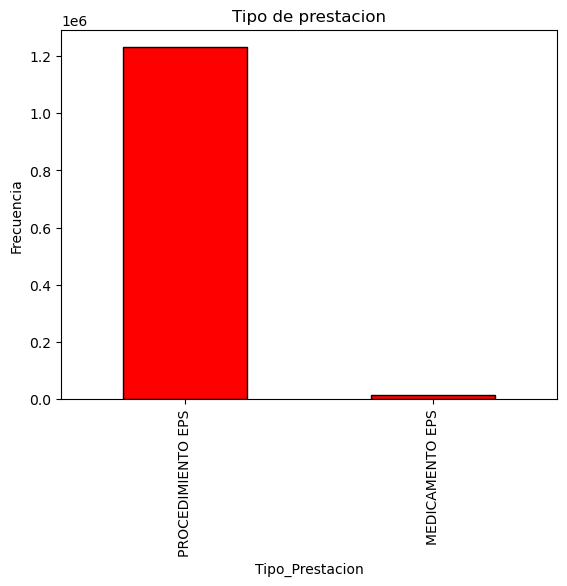

In [90]:
# el tipo de presentacion
df_autorizaciones['Tipo_Prestacion'].value_counts().plot(kind='bar',color='red', edgecolor='black')
plt.title('Tipo de prestacion')
plt.ylabel('Frecuencia')
plt.show()

# el canal que mas se utiliza para las compras es online 

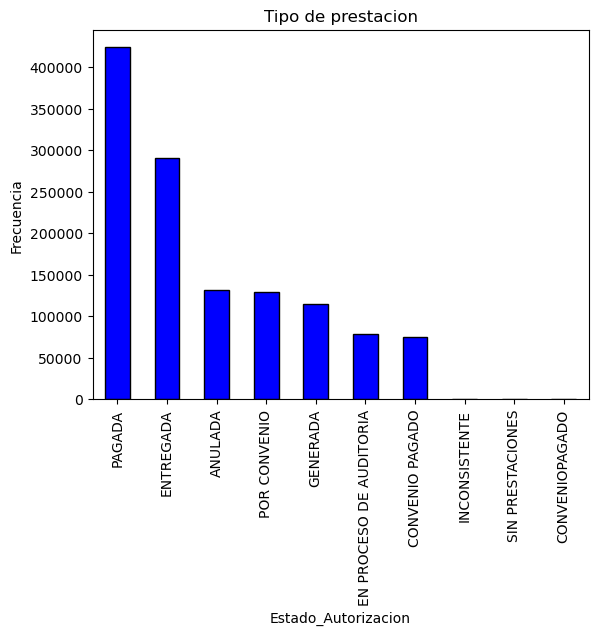

In [93]:


# el tipo de presentacion
df_autorizaciones['Estado_Autorizacion'].value_counts().plot(kind='bar',color='blue', edgecolor='black')
plt.title('Tipo de prestacion')
plt.ylabel('Frecuencia')
plt.show()

In [37]:
# guardo los datos limpios en un archivo csv
df_autorizaciones.to_csv("Autorizaciones_limpio.csv",index=False ,encoding='utf-8-sig')  # Guarda en CSV con el índice
df_salario.to_csv("Salario_limpio.csv",index=False ,encoding='utf-8-sig') 
